# Settings

In [180]:
run_beamforming = True
beamform_interpolated = True

parameters_file_path = "./parameters/002_simulation.json"

#saved names
beamformed_image_name = "001_2obj_1_2pitch_7angle"

# Imports

In [181]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import json
from scipy import signal

# Import parameters

In [182]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [183]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"]

    return params

In [184]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = 1500 #speed of sound

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.010008000000000001 m


## Objects

In [185]:
class Objects:
    def __init__(self, depth, position, array_length, samples, upsampled_samples, angles_len):
        self.depth = depth
        self.position = position
        self.delays = np.zeros(shape = (array_length, angles_len))
        self.rf_matrix = np.zeros(shape = (samples, array_length, angles_len))
        self.rf_matrix_upsampled = np.zeros(shape = (upsampled_samples, array_length, angles_len))
        self.effective_array_length = 0
        self.effective_angle = 0

In [186]:
objects = []

for reflector in params["objects"]:
    objects.append(
        Objects(
            reflector["depth"], 
            reflector["position"], 
            params["array"]["length"], 
            params["rf"]["samples"], 
            params["rf"]["upsampled_samples"],
            len(params["rf"]["angles"])
            )    
        )

# Signals

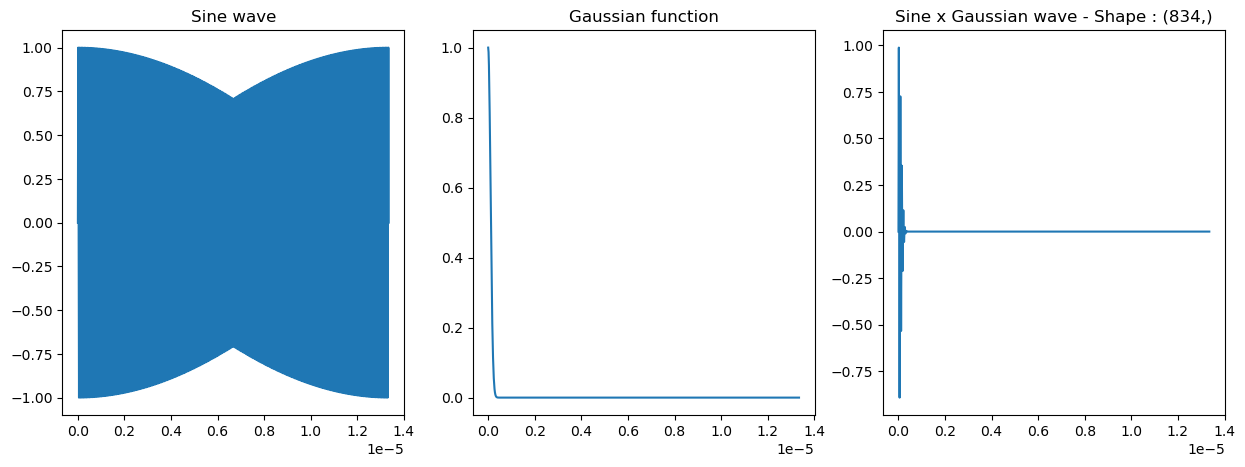

In [187]:
gaussian_std = 0.0000001

def sine_wave(frequency, timestep):
    return np.sin(2*np.pi*frequency*timestep)

def gaussian_function(timestep, std):
    return np.exp(-timestep**2 / (2 * std**2))

def generate_wave(frequency, timestep, std):
    return sine_wave(frequency, timestep) * gaussian_function(timestep, std)

fig, ax = plt.subplots(1,3, figsize=(15,5))

wave1, wave2, wave3 = sine_wave(params['rf']['frequency'], time), gaussian_function(time, gaussian_std), generate_wave(params['rf']['frequency'], time, gaussian_std)
ax[0].plot(time, wave1)
ax[0].set_title("Sine wave")

ax[1].plot(time, wave2)
ax[1].set_title("Gaussian function")

ax[2].plot(time, wave3)
ax[2].set_title(f"Sine x Gaussian wave - Shape : {wave3.shape}")
plt.show()

# Interpolation

In [188]:
def zero_stuffing(rf_matrices_summed, interpolation_factor, upsampled_samples):
    interpolation_factor = interpolation_factor - 1
    new_matrices_summed = np.zeros((upsampled_samples, rf_matrices_summed.shape[1], rf_matrices_summed.shape[2]))
    
    for i in range(rf_matrices_summed.shape[2]): #for each angle
        for j in range(rf_matrices_summed.shape[1]): #for each transducer
            for k in range(rf_matrices_summed.shape[0]): #for each sample
                idx_new = k + (interpolation_factor * k)
                new_matrices_summed[idx_new, j, i] = rf_matrices_summed[k, j, i]

    return new_matrices_summed

In [189]:
def get_filtered_matrices(zero_stuffed_rf_matrices_summed, frequency, sampling_frequency):
    filtered_rf_matrices_summed = np.zeros((zero_stuffed_rf_matrices_summed.shape[0], zero_stuffed_rf_matrices_summed.shape[1], zero_stuffed_rf_matrices_summed.shape[2]))

    new_samples = zero_stuffed_rf_matrices_summed.shape[0]
    cutoff_freq = 0.50 * frequency #use Nyquist frequency as cutoff frequency
    
    filtering_function = signal.firwin(new_samples, cutoff_freq, fs=sampling_frequency)

    for i in range(0, zero_stuffed_rf_matrices_summed.shape[2]): #for each angle
        for j in range(0, zero_stuffed_rf_matrices_summed.shape[1]): #for each transducer
            filtered_rf_matrices_summed[:,j,i] = np.convolve(zero_stuffed_rf_matrices_summed[:,j,i], filtering_function, mode='same')

    return filtered_rf_matrices_summed

# Delays

In [190]:
def delay_function(object_depth, object_position, speed_sound, array_position, pitch, angle):
    return ((object_depth * np.cos(angle * np.pi/180) + object_position * np.sin(angle * np.pi/180)) / speed_sound)  + (np.sqrt(object_depth**2 + (array_position * pitch - object_position)**2) / speed_sound)

In [191]:
def get_delays(objects, c, pitch, array_length, angles, destination="./data/csv/delays/"):
    for i in range(0, len(angles)):
        for j in range(0, len(objects)):
            for k in range(0, array_length):
                 objects[j].delays[k, i] = delay_function(object_depth=objects[j].depth, object_position=objects[j].position, speed_sound=c, array_position=k, pitch=pitch, angle=angles[i])

    for i, reflector in enumerate(objects):
        np.save(f"{destination}delay_matrix_object{i+1}", reflector.delays)

get_delays(objects, C, params["array"]["pitch"], params["array"]["length"], params["rf"]["angles"])

## Showing delay results

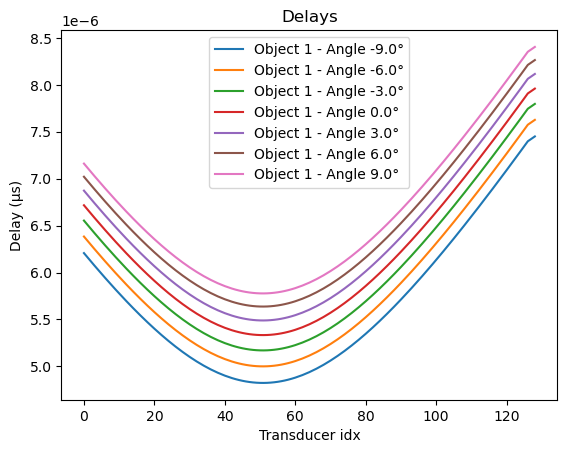

In [192]:
plt.figure()    
for i in range (0, len(params["rf"]["angles"])):
    for j in range(0, len(objects)):
        plt.plot(pos, objects[j].delays[:,i], label = f"Object {j+1} - Angle {params["rf"]["angles"][i]}°")
plt.title("Delays")
plt.xlabel("Transducer idx")
plt.ylabel("Delay (µs)")
plt.legend()
plt.show()

## Find object effective aperture 

In [193]:
def find_object_effective_aperture(objects, aperture):
    for i in range(0, len(objects)):
        objects[i].effective_array_length =  objects[i].depth / aperture

find_object_effective_aperture(objects, params["array"]["aperture"])

## Wave delays

In [194]:
def is_in_transducer_range(current_object : Objects, current_transducer, pitch):
    if current_transducer * pitch <= current_object.position - current_object.effective_array_length / 2 or current_transducer * pitch >= current_object.position + current_object.effective_array_length / 2:
        return 0
    else:
        return np.cos(np.abs(current_object.position - current_transducer * pitch) / current_object.effective_array_length) ** 18

In [195]:
def get_rf_matrices(objects : Objects, frequency, time, array_length, pitch, gaussian_std, samples, upsampled_samples, interpolation_factor, sampling_rate, angles = [0], destination="./data/csv/rf_data/"):
    rf_matrices_summed = np.zeros((samples, array_length, len(angles)))
    rf_matrices_upsampled_summed = np.zeros((upsampled_samples, array_length, len(angles)))

    for i in range(0, len(angles)):
        for j in range(0, len(objects)):
            for k in range(array_length):
                #for each transducer, generate the wave with the corresponding delay
                objects[j].rf_matrix[:,k,i] += generate_wave(frequency, time - objects[j].delays[k,i], gaussian_std) * is_in_transducer_range(objects[j], k, pitch)
            
            rf_matrices_summed[:,:,i] += objects[j].rf_matrix[:,:,i] 

    for i, reflector in enumerate(objects):
        np.save(f"{destination}rf_matrix_object{i+1}", reflector.rf_matrix)

        temp_zero_stuffed = zero_stuffing(reflector.rf_matrix, interpolation_factor, upsampled_samples)
        temp_upsampled = get_filtered_matrices(temp_zero_stuffed, frequency, sampling_rate)

        objects[i].rf_matrix_upsampled = temp_upsampled
        rf_matrices_upsampled_summed += temp_upsampled
        
        np.save(f"{destination}rf_matrix_upsampled_object{i+1}", temp_upsampled)

    np.save(f"{destination}rf_matrix_upsampled_summed", rf_matrices_upsampled_summed)
    np.save(f"{destination}rf_matrix_summed", rf_matrices_summed)
    return rf_matrices_summed, rf_matrices_upsampled_summed

In [196]:
rf_matrices_summed, rf_matrices_upsampled_summed = get_rf_matrices(objects, 
                                                                    params["rf"]["frequency"],
                                                                    time,  
                                                                    params["array"]["length"],  
                                                                    params["array"]["pitch"],  
                                                                    gaussian_std,  
                                                                    params["rf"]["samples"],  
                                                                    params["rf"]["upsampled_samples"],
                                                                    params["rf"]["interpolation_factor"],
                                                                    params["rf"]["sampling_rate"],
                                                                    params["rf"]["angles"]
                                                                    )

## Showing wave results

In [197]:
def plot_rf_matrices_heatmaps(rf_matrices_summed, angles = [0]):
    n_matrices = rf_matrices_summed.shape[2]
    n_cols = min(3, n_matrices)
    n_rows = (n_matrices + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*5, n_rows*4))
    
    if n_matrices > 1 and n_rows > 1:
        axes = axes.flatten()
    elif n_matrices > 1:
        #if single row but multiple columns
        axes = axes
    else:
        #if just one plot - otherwise obj is not subscriptable
        axes = [axes]
    
    for i in range(n_matrices):
        if i < len(axes):
            im = axes[i].imshow(np.abs(rf_matrices_summed[:,:,i]), aspect='auto', cmap='hot')
            axes[i].set_title(f'RF Matrix at Angle {angles[i]}°')
            axes[i].set_xlabel('Transducer idx')
            axes[i].set_ylabel('Sample idx')
            fig.colorbar(im, ax=axes[i], label='Amplitude')

    for i in range(n_matrices, len(axes)):
        fig.delaxes(axes[i]) #remove empty plots
    
    plt.tight_layout()
    plt.savefig('./data/images/rf_matrices.png')
    plt.show()

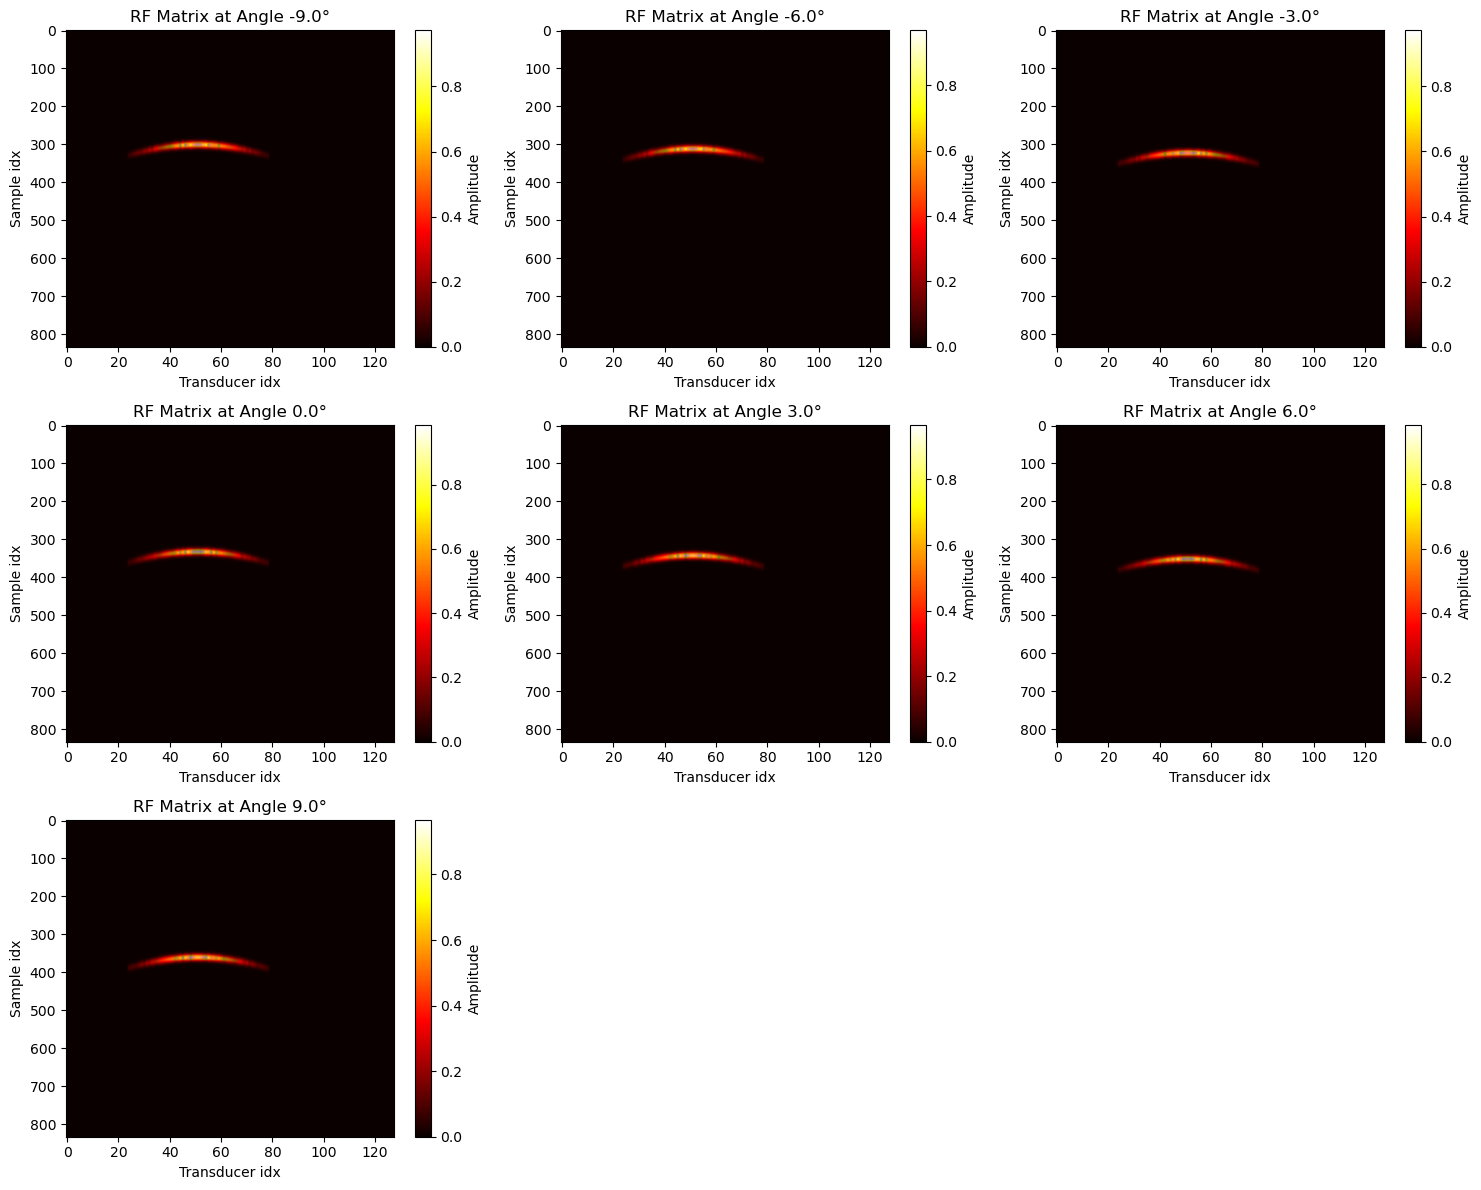

In [198]:
plot_rf_matrices_heatmaps(rf_matrices_summed, params["rf"]["angles"])

In [199]:
1 / params["rf"]["sampling_rate"]

1.6e-08

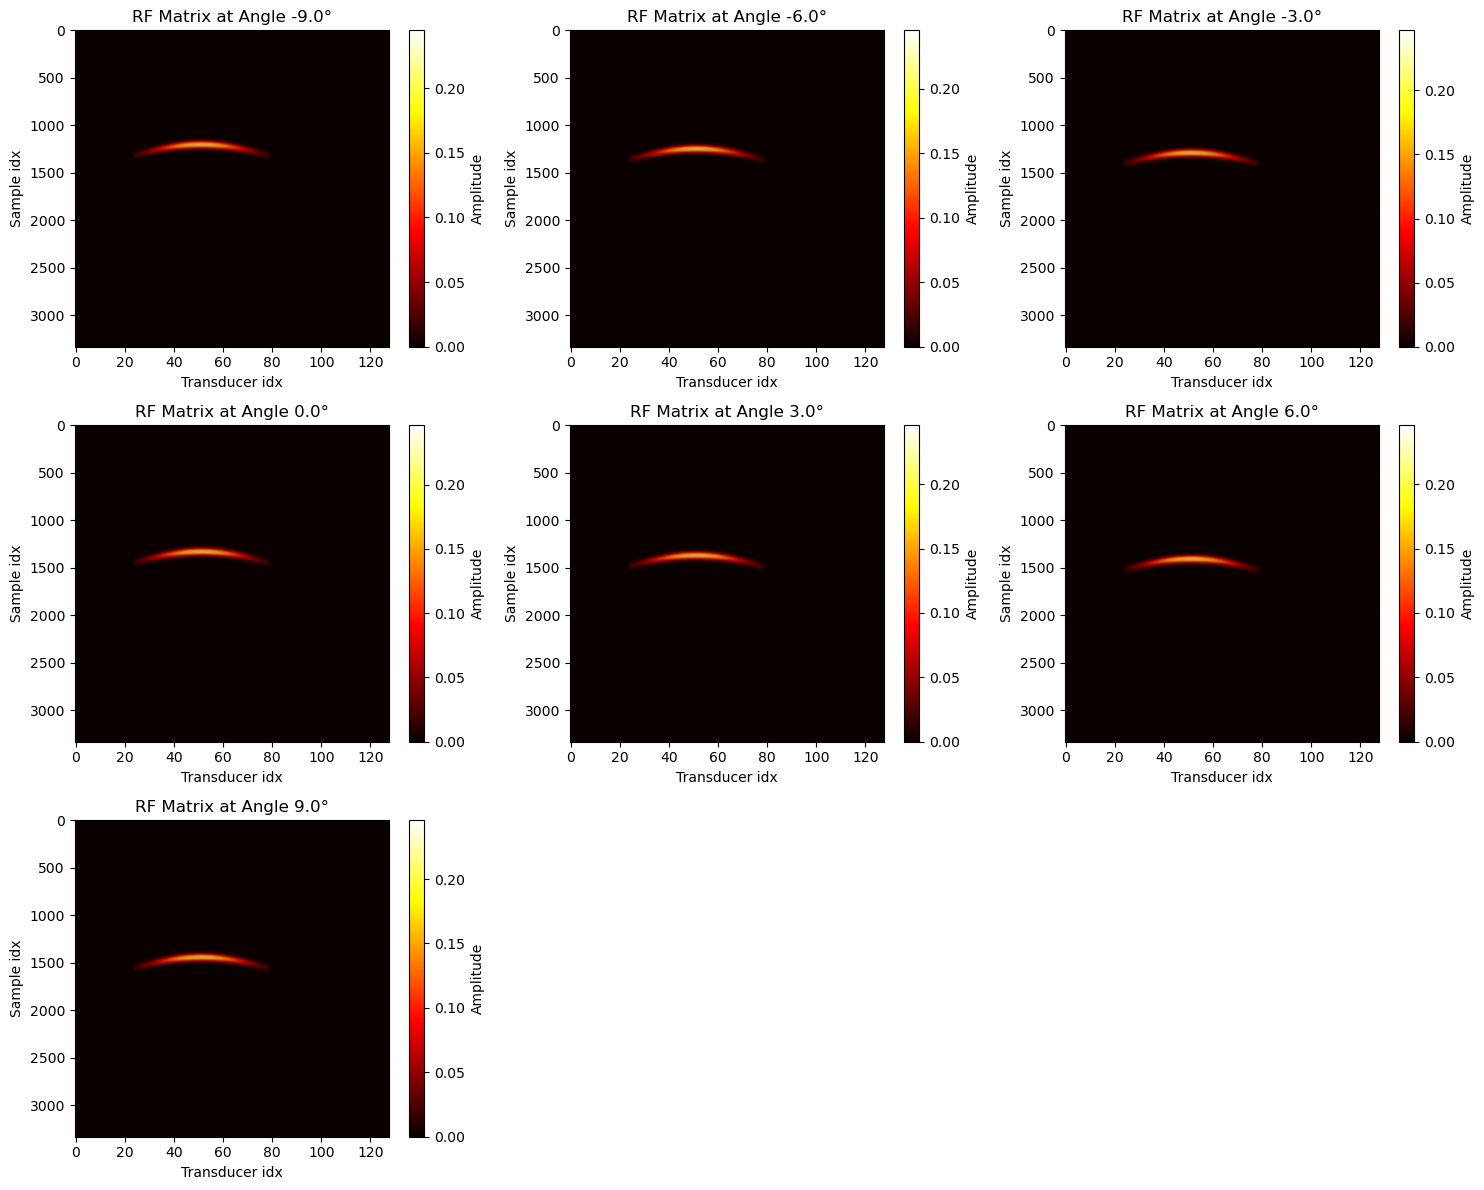

In [200]:
plot_rf_matrices_heatmaps(rf_matrices_upsampled_summed, params["rf"]["angles"])

# Beamforming

In [201]:
def save_beamformed_data(bf_matrix, filename, destination="./data/csv/beamformed/"):
    np.save(f"{destination}{filename}", bf_matrix)
    print(f"Beamformed data saved at: {destination}{filename}.npy")

In [202]:
@njit(parallel=True)
def beamforming_opt(rf_summed_matrices, nx, nz, dx, dz, x0, z0, delay0, pitch, c, array_length, samples, sampling_rate, angles = [0]):
    bf_matrices = np.zeros((nz, nx, len(angles)))

    for i in range(0, len(angles)): #for each angle

        for j in range(x0, nx): #for each lateral res sample

            for k in range(z0, nz): #for vertical res sample

                depth = dz*k
                position = dx*j
                # we normalize the index to the total array length

                for l in range(0, array_length): #for each transducer

                    delay = ((depth * np.cos(angles[i] * np.pi/180) + position * np.sin(angles[i] * np.pi/180)) / c)  + (np.sqrt(depth**2 + (l * pitch - position)**2) / c)
                    delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)

                    if delay_idx < samples:
                        bf_matrices[k,j,i] += rf_summed_matrices[delay_idx, l, i] #we take sample in calculated rf_matrix (faster than recalculating)
        
        print(f"Beamforming done for angle",angles[i],'°')
    return bf_matrices

In [203]:
if run_beamforming:
    bf_matrices = beamforming_opt(
        rf_matrices_upsampled_summed if beamform_interpolated else rf_matrices_summed, 
        params["image"]["nx"], 
        params["image"]["nz"],
        params["image"]["dx"],
        params["image"]["dz"],
        params["image"]["x0"],
        params["image"]["z0"],
        params["rf"]["delay0"],
        params["array"]["pitch"], 
        C, 
        params["array"]["length"], 
        params["rf"]["upsampled_samples"] if beamform_interpolated else params["rf"]["samples"], 
        params["rf"]["upsampled_sampling_rate"] if beamform_interpolated else params["rf"]["sampling_rate"], 
        angles=params["rf"]["angles"]
    )

    save_beamformed_data(bf_matrices, beamformed_image_name, destination="./data/csv/raw_beamformed/")

    bf_matrix_summed = np.sum(bf_matrices, axis=2)

    save_beamformed_data(bf_matrix_summed, beamformed_image_name)

Beamforming done for angle -9.0 °
Beamforming done for angle -6.0 °
Beamforming done for angle -3.0 °
Beamforming done for angle 0.0 °
Beamforming done for angle 3.0 °
Beamforming done for angle 6.0 °
Beamforming done for angle 9.0 °
Beamformed data saved at: ./data/csv/raw_beamformed/001_2obj_1_2pitch_7angle.npy
Beamformed data saved at: ./data/csv/beamformed/001_2obj_1_2pitch_7angle.npy


## Visualize beamformed image

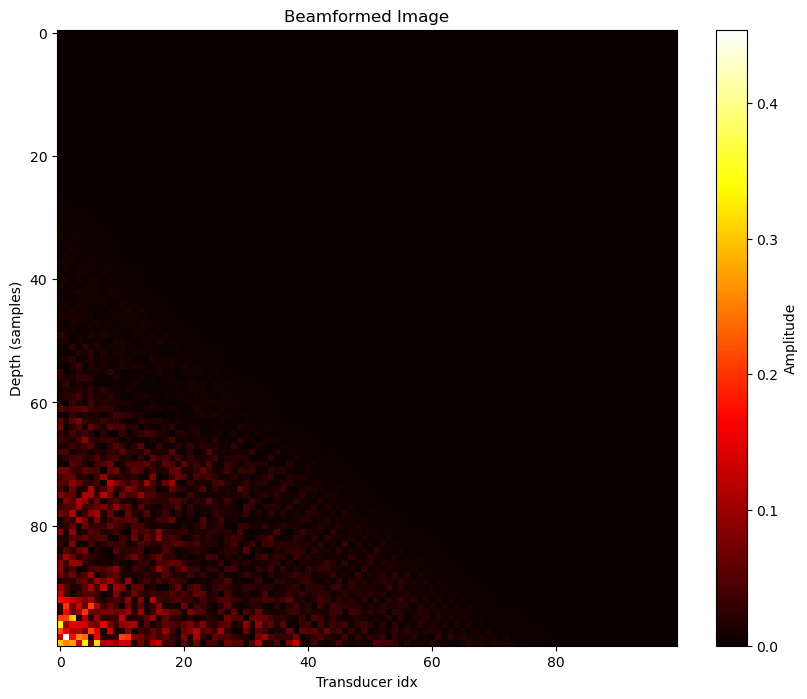

In [204]:
if run_beamforming:
    plt.figure(figsize=(10, 8))
    plt.imshow(np.abs(bf_matrix_summed), cmap='hot', aspect='auto')
    plt.title("Beamformed Image")
    plt.xlabel("Transducer idx")
    plt.ylabel("Depth (samples)")
    plt.colorbar(label="Amplitude")
    plt.savefig("./data/images/bf_image_angles.png")
    plt.show()